# Tutorial 6 — Correlations and compression in DNA sequences

Notebook of the programming section of chapter 6 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).
Each section below corresponds to one question of the tutorial. All analyses loop over the five sequences:
`random_seq_I`, `random_seq_T`, `lambdaphage`, `H1N1_1918`, `H1N1_2008`.

**How to run it.** Run all cells from top to bottom.
* *Locally (Jupyter):* run it from its folder; it needs the package `zstandard` (version 0.23.0, because
  the size of the compressed sequences depends on the version).
* *On Google Colab:* [open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_6/Tutorial_6.ipynb)
  and run all cells; the package and the data files are installed and downloaded automatically.

The random number generators are seeded, so that the notebook reproduces the figures and numbers of the book.

In [2]:
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

import os, sys, subprocess, urllib.request, importlib.metadata
IN_COLAB = 'google.colab' in sys.modules

# zstandard is pinned, because the size of the compressed sequences depends on its version
try:
    installed = importlib.metadata.version('zstandard')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.23.0':
    if IN_COLAB or installed is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'zstandard==0.23.0'], check=True)
    else:
        print(f'Warning: zstandard {installed} is installed; the book uses zstandard 0.23.0 '
              '(pip install zstandard==0.23.0), so the compressed sizes may differ slightly.')

import numpy as np
import math
import random
import matplotlib.pyplot as plt
import numpy.linalg as LA
import zstandard as zstd
%matplotlib inline
print('zstandard', importlib.metadata.version('zstandard'))

# Book repository, from which missing data files are downloaded
BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'
FOLDER = 'Tutorial_6/'

def get_data(fname, sources=()):
    """Return fname if it is in the working folder; otherwise try to download it from the
    book repository and from `sources`; on Colab, as a last resort, ask to upload it."""
    if os.path.exists(fname):
        return fname
    for url in [BOOK_REPO + FOLDER + fname] + list(sources):
        try:
            urllib.request.urlretrieve(url, fname)
            print('downloaded', fname, 'from', url)
            return fname
        except Exception:
            pass
    if IN_COLAB:
        from google.colab import files
        print(f'Please upload {fname}')
        files.upload()
        if os.path.exists(fname):
            return fname
    raise FileNotFoundError(f'{fname} not found: download it into the folder of this notebook')

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

zstandard 0.23.0


## Generate a random sequence with given transition probabilities
(This is how the two artificial sequences were generated; the files used below are provided.)

In [4]:
def prob_gen_T():
  P=np.zeros((4,4))
  for b in range(4):
    c=b
    while c==b:
      c=np.random.randint(4)
    for a in range(4):
      if a==c or a==b:
          P[a,b]=0.45
      else:
          P[a,b]=0.05
  return P

def BtoI(a):
  if a==0 or a==3:
    return -1
  else:
    return 1

def prob_gen_Ising(J):
  pstay=np.exp(J)/(np.exp(J)+np.exp(-J))
  P=np.zeros((4,4))
  for b in range(4):
    for a in range(4):
      if BtoI(a)==BtoI(b):
          P[a,b]=pstay/2.
      else:
          P[a,b]=(1-pstay)/2.
  return P

P=prob_gen_Ising(3)
print("Generating probability:\n",P)

def generate_random_seq(L,P):
  alphabet=['a','c','g','t']
  rseq=[]
  rseq.append(np.random.randint(4))
  for i in range(L-1):
    pnext=P[:,rseq[-1]]
    rseq.append(np.random.choice(4,p=pnext))
  return [alphabet[i] for i in rseq]

Generating probability:
 [[0.49876369 0.00123631 0.00123631 0.49876369]
 [0.00123631 0.49876369 0.49876369 0.00123631]
 [0.00123631 0.49876369 0.49876369 0.00123631]
 [0.49876369 0.00123631 0.00123631 0.49876369]]


In [5]:
# Uncomment to generate a new artificial sequence
#np.savetxt("random_seq.txt",generate_random_seq(50000,P),fmt='%s',delimiter='',newline='')

## Read the sequences

* `random_seq_I`, `random_seq_T`: two artificial sequences of 50,000 bases, generated with the code above.
* `lambdaphage`: genome of the bacteriophage $\lambda$ (GenBank J02459).
* `H1N1_1918`, `H1N1_2008`: PB2 segment of the influenza A H1N1 virus of the 1918 pandemic
  (ENA DQ208309) and of a 2008 seasonal strain (GenBank CY044380).

The files are read from the folder of the notebook or, if missing, downloaded from the book repository.
Only the letters `a`, `c`, `g`, `t` are kept, so the files can contain numbers, spaces and headers.

In [7]:
def letter2number(a):
    #to convert the basis letters into integer numbers from 1 to 4
    switcher = {
        'a': 1,
        'c': 2,
        'g': 3,
        't': 4,
    }
    return switcher.get(a,0)

# Open the file and write a list containing all lines. Join them.
def read_seq(file):
  data=open(file, 'r')
  phageread1 = data.readlines()
  phageread2 = ''.join(phageread1)
  data.close()
  # Convert the letters into numbers from 0 to 3 (a=0, c=1, g=2, t=3)
  rseq = []
  for i in range(len(phageread2)):
      y = letter2number(phageread2[i])
      if (y!=0):
          rseq.append(y-1)
  return rseq

names = ['random_seq_I', 'random_seq_T', 'lambdaphage', 'H1N1_1918', 'H1N1_2008']
seqs = {name: read_seq(get_data(name+'.txt')) for name in names}
for name in names:
    print(f"{name:13s}  L = {len(seqs[name])}")

random_seq_I   L = 50000
random_seq_T   L = 50000
lambdaphage    L = 48502
H1N1_1918      L = 2280
H1N1_2008      L = 2296


## Questions 1-2: single-base probabilities, entropy, and compression

In [9]:
# Estimate letter probabilities
def letter_prob(seq):
  L=len(seq)
  return np.array([seq.count(a)/L for a in range(4)])

def entropy(p):
  p=np.asarray(p)
  p=p[p>0]
  return -np.sum(p*np.log2(p))

# Write the sequence in such a way that each symbol occupies two bits.
def pack_2bit_integers(integers):
    packed_data = bytearray()
    current_byte = 0
    bits_written = 0

    for value in integers:
        # Make sure the value is within the 2-bit range
        value = value & 0b11

        # Pack the value into the current byte
        current_byte = (current_byte << 2) | value
        bits_written += 2

        # If we have filled a byte, append it to the result
        if bits_written == 8:
            packed_data.append(current_byte)
            current_byte = 0
            bits_written = 0

    # If there are remaining bits, append the last byte
    if bits_written > 0:
        packed_data.append(current_byte << (8 - bits_written))

    return packed_data

In [10]:
# NOTE: sys.getsizeof returns the size of the Python object, which includes a fixed
# overhead of 33 bytes on top of the compressed data (see the print below).
# This is negligible for L ~ 50,000 (about 0.005 bits per base), but it amounts to
# about 0.12 bits per base for the two influenza sequences (L ~ 2300).
ov = sys.getsizeof(b'')
print("Python overhead of a bytes object:", ov, "bytes will be subtracted\n")

compressor = zstd.ZstdCompressor()
H_iid, H_comp = {}, {}
for name in names:
    seq=seqs[name]; L=len(seq)
    p=letter_prob(seq)
    H_iid[name]=entropy(p)
    seqCC = compressor.compress(pack_2bit_integers(seq))
    H_comp[name]=(sys.getsizeof(seqCC)-ov)*8/L
    print(f"{name:13s} p(A,C,G,T) = {np.round(p,4)}   H_iid = {H_iid[name]:.3f}   H_comp = {H_comp[name]:.3f} bits/base")

Python overhead of a bytes object: 33 bytes will be subtracted

random_seq_I  p(A,C,G,T) = [0.2494 0.2512 0.2527 0.2467]   H_iid = 2.000   H_comp = 1.296 bits/base
random_seq_T  p(A,C,G,T) = [0.3041 0.0831 0.3276 0.2852]   H_iid = 1.864   H_comp = 1.589 bits/base
lambdaphage   p(A,C,G,T) = [0.2543 0.2343 0.2643 0.2471]   H_iid = 1.999   H_comp = 2.002 bits/base
H1N1_1918     p(A,C,G,T) = [0.332  0.182  0.2618 0.2241]   H_iid = 1.965   H_comp = 2.035 bits/base
H1N1_2008     p(A,C,G,T) = [0.3471 0.1781 0.2422 0.2326]   H_iid = 1.958   H_comp = 2.035 bits/base


## Question 3: randomly shuffled sequences

In [12]:
random.seed(0)
H_shuffle = {}
for name in names:
    seqS = seqs[name].copy()
    random.shuffle(seqS)
    seqCC = compressor.compress(pack_2bit_integers(seqS))
    H_shuffle[name]=(sys.getsizeof(seqCC)-ov)*8/len(seqS)
    print(f"{name:13s} H_iid = {H_iid[name]:.3f}   H_comp = {H_comp[name]:.3f}   H_comp(shuffled) = {H_shuffle[name]:.3f} bits/base")

random_seq_I  H_iid = 2.000   H_comp = 1.296   H_comp(shuffled) = 2.002 bits/base
random_seq_T  H_iid = 1.864   H_comp = 1.589   H_comp(shuffled) = 1.885 bits/base
lambdaphage   H_iid = 1.999   H_comp = 2.002   H_comp(shuffled) = 2.002 bits/base
H1N1_1918     H_iid = 1.965   H_comp = 2.035   H_comp(shuffled) = 2.035 bits/base
H1N1_2008     H_iid = 1.958   H_comp = 2.035   H_comp(shuffled) = 2.035 bits/base


## Question 4: conditional probabilities and CpG motifs

Note on rounding. In the tables of the book, the probabilities are rounded to the digits shown; when the rounded values of a column do not sum to 1, one of them has been adjusted by one unit in the last digit so that they do: this is the case for the base frequencies of `H1N1_1918` and `H1N1_2008` (e.g. $p(T)=0.2241$ printed here, $0.2242$ in the book), and for the conditional probability $p(T|G)$ of `random_seq_T` ($0.051$ here, $0.052$ in the book).

In [14]:
# Joint probability of two consecutive symbols: p2(a,b) = p(sigma_{i+1}=a, sigma_i=b)
# Conditional probability: pC(a|b) = p(sigma_{i+1}=a | sigma_i=b)
# Observed/expected ratio: pCC(a,b) = p2[a,b] / (p(a) p(b)) = pC[a|b]/p(a)
def pair_stats(seq):
  L=len(seq)
  p=letter_prob(seq)
  seqarray = np.array(seq)
  p2=np.zeros((4,4))
  for a in range(4):
    for b in range(4):
      p2[a,b] = np.sum((seqarray[:-1] == b) & (seqarray[1:] == a))/(L-1)
  pC=np.zeros((4,4))
  pCC=np.zeros((4,4))
  for a in range(4):
    for b in range(4):
      pC[a,b]= p2[a,b]/p[b]
      pCC[a,b]=p2[a,b]/(p[b]*p[a])
  return p, p2, pC, pCC

p, p2, pC, pCC = pair_stats(seqs['random_seq_T'])
np.set_printoptions(precision=3, suppress=True)
print("random_seq_T, conditional probability p(sigma_{i+1}|sigma_i) (columns: sigma_i = A,C,G,T):\n", pC)
print("Check sum", np.sum(pC,axis=0), "\n")

# A=0, C=1, G=2, T=3. CpG: C at i, G at i+1 -> [2,1]; GpC: G at i, C at i+1 -> [1,2]
for name in names:
    p, p2, pC, pCC = pair_stats(seqs[name])
    print(f"{name:13s} p(G|C) = {pC[2,1]:.3f}   CpG obs/exp = {pCC[2,1]:.2f}   GpC obs/exp = {pCC[1,2]:.2f}   p(C) = {p[1]:.3f}  p(G) = {p[2]:.3f}")

random_seq_T, conditional probability p(sigma_{i+1}|sigma_i) (columns: sigma_i = A,C,G,T):
 [[0.458 0.055 0.448 0.048]
 [0.051 0.457 0.049 0.047]
 [0.048 0.439 0.451 0.451]
 [0.443 0.049 0.051 0.454]]
Check sum [1. 1. 1. 1.] 

random_seq_I  p(G|C) = 0.498   CpG obs/exp = 1.97   GpC obs/exp = 1.97   p(C) = 0.251  p(G) = 0.253
random_seq_T  p(G|C) = 0.439   CpG obs/exp = 1.34   GpC obs/exp = 0.59   p(C) = 0.083  p(G) = 0.328
lambdaphage   p(G|C) = 0.274   CpG obs/exp = 1.04   GpC obs/exp = 1.20   p(C) = 0.234  p(G) = 0.264
H1N1_1918     p(G|C) = 0.121   CpG obs/exp = 0.46   GpC obs/exp = 0.88   p(C) = 0.182  p(G) = 0.262
H1N1_2008     p(G|C) = 0.086   CpG obs/exp = 0.35   GpC obs/exp = 0.91   p(C) = 0.178  p(G) = 0.242


## Question 5: entropy of the nearest-neighbour model

In [16]:
def H_nn_per_symbol(seq):
  p, p2, pC, pCC = pair_stats(seq)
  L=len(seq)
  #First symbol
  curr_p=p
  curr_s=entropy(p)
  #Next symbols
  for i in range(2,L+1):
    si=0
    for a in range(4):
      for b in range(4):
        if pC[a,b]>0:
          si-=pC[a,b]*curr_p[b]*np.log2(pC[a,b])
    curr_s+=si
    curr_p=np.dot(pC,curr_p)
  return curr_s/L

H_nn = {}
for name in names:
    H_nn[name]=H_nn_per_symbol(seqs[name])
    print(f"{name:13s} H_iid = {H_iid[name]:.3f}   H_nn = {H_nn[name]:.3f}   H_comp = {H_comp[name]:.3f} bits/base")

random_seq_I  H_iid = 2.000   H_nn = 1.025   H_comp = 1.296 bits/base
random_seq_T  H_iid = 1.864   H_nn = 1.465   H_comp = 1.589 bits/base
lambdaphage   H_iid = 1.999   H_nn = 1.984   H_comp = 2.002 bits/base
H1N1_1918     H_iid = 1.965   H_nn = 1.926   H_comp = 2.035 bits/base
H1N1_2008     H_iid = 1.958   H_nn = 1.920   H_comp = 2.035 bits/base


## Question 6: adaptive order-$k$ Markov coder

Model: $\hat p_i(a|c) = [n_i(c,a)+1]/[n_i(c)+4]$, where the counts $n_i$ include only the bases already encoded (Laplace's rule).
Coder: arithmetic coding with exact rational numbers (`fractions.Fraction`).

In [18]:
from fractions import Fraction

def prediction(counts, context):
  # Laplace's rule: (n(c,a)+1)/(n(c)+4), uniform for a context never seen before
  c = counts.get(context, [0,0,0,0])
  tot = sum(c)
  return [Fraction(c[a]+1, tot+4) for a in range(4)]

def arithmetic_encode(x, k, verbose=False):
  counts = {}
  low, width = Fraction(0), Fraction(1)
  for i in range(len(x)):
    context = tuple(x[max(0,i-k):i])
    p = prediction(counts, context)
    a = x[i]
    low += width*sum(p[:a])        # sub-intervals in the order A, C, G, T
    width *= p[a]
    counts.setdefault(context, [0,0,0,0])[a] += 1
    if verbose:
      print(f"step {i+1}: base {'ACGT'[a]}, context {''.join('ACGT'[b] for b in context) or '-'},"
            f" p = {[str(q) for q in p]}, interval [{float(low)}, {float(low+width)})")
  # shortest binary fraction whose dyadic interval lies inside [low, low+width)
  n = 1
  while True:
    m = -((-low.numerator*2**n)//low.denominator)    # ceil(low*2^n)
    if Fraction(m+1, 2**n) <= low+width:
      return format(m, f'0{n}b'), math.log2(width.denominator) - math.log2(width.numerator)   # K = -log2(width)
    n += 1

def arithmetic_decode(bits, L, k):
  v = Fraction(int(bits,2), 2**len(bits))
  counts = {}
  low, width = Fraction(0), Fraction(1)
  x = []
  for i in range(L):
    context = tuple(x[max(0,i-k):i])
    p = prediction(counts, context)      # same prediction as the encoder
    cumu = low
    for a in range(4):
      if v < cumu + width*p[a]:
        break
      cumu += width*p[a]
    low, width = cumu, width*p[a]
    x.append(a)
    counts.setdefault(context, [0,0,0,0])[a] += 1
  return x

# Worked example of the text: ACAC with k=1
example=[0,1,0,1]
bits, K = arithmetic_encode(example, 1, verbose=True)
print("code:", bits, f"({len(bits)} bits, K = {K:.2f})")
print("decoded:", ''.join('ACGT'[a] for a in arithmetic_decode(bits, 4, 1)))

step 1: base A, context -, p = ['1/4', '1/4', '1/4', '1/4'], interval [0.0, 0.25)
step 2: base C, context A, p = ['1/4', '1/4', '1/4', '1/4'], interval [0.0625, 0.125)
step 3: base A, context C, p = ['1/4', '1/4', '1/4', '1/4'], interval [0.0625, 0.078125)
step 4: base C, context A, p = ['1/5', '2/5', '1/5', '1/5'], interval [0.065625, 0.071875)
code: 00010001 (8 bits, K = 7.32)
decoded: ACAC


In [19]:
# Encode and decode the whole H1N1_1918 sequence with k=1
x = seqs['H1N1_1918']
bits, K = arithmetic_encode(x, 1)
print(f"number of bits: {len(bits)}   K = {K:.1f}   ({len(bits)/len(x):.3f} bits per base)")
print("decoded sequence identical to the original:", arithmetic_decode(bits, len(x), 1) == x)

number of bits: 4438   K = 4436.7   (1.946 bits per base)
decoded sequence identical to the original: True


In [20]:
# Code length K/L (no need to encode explicitly)
def code_length(seq, k):
  counts = {}
  bits = 0.
  for i in range(len(seq)):
    context = tuple(seq[max(0,i-k):i])
    c = counts.setdefault(context, [0,0,0,0])
    bits -= np.log2((c[seq[i]]+1)/(sum(c)+4))
    c[seq[i]] += 1
  return bits/len(seq)

kmax = 8
K_L = {name: [code_length(seqs[name], k) for k in range(kmax+1)] for name in names}
print("K/L (bits per base)")
print(f"{'k':>3s}" + ''.join(f"{n:>14s}" for n in names))
for k in range(kmax+1):
  print(f"{k:3d}" + ''.join(f"{K_L[n][k]:14.3f}" for n in names))

K/L (bits per base)
  k  random_seq_I  random_seq_T   lambdaphage     H1N1_1918     H1N1_2008
  0         2.000         1.864         1.999         1.972         1.964
  1         1.025         1.467         1.986         1.946         1.939
  2         1.028         1.470         1.968         1.971         1.964
  3         1.032         1.477         1.966         2.013         2.014
  4         1.039         1.494         1.981         2.055         2.044
  5         1.052         1.524         2.018         2.050         2.043
  6         1.073         1.576         2.054         2.020         2.019
  7         1.106         1.644         2.046         2.008         2.010
  8         1.160         1.727         2.021         2.001         2.001


## Question 7: mutual information between bases at distance $r$

$I_r = \sum_{a,b} p_r(a,b)\log_2\frac{p_r(a,b)}{p(a)p(b)}$, where $p_r(a,b)$ is the frequency of pairs $(\sigma_i=a,\sigma_{i+r}=b)$.
We compare the data with (i) the shuffled sequence, which measures the finite-sample bias, and (ii) the prediction of the
nearest-neighbour model for $L\to\infty$: $p_r(a,b) = [\mathbb{P}^r]_{ba}\,\pi_a$, with $\pi$ the stationary distribution, $\mathbb{P}\pi=\pi$.

In [22]:
def MI_data(seq, r):
  x=np.array(seq)
  J=np.zeros((4,4))
  np.add.at(J, (x[:-r], x[r:]), 1)   # J[a,b] = number of pairs sigma_i=a, sigma_{i+r}=b
  J/=J.sum()
  pa=J.sum(axis=1); pb=J.sum(axis=0)
  nz=J>0
  return np.sum(J[nz]*np.log2(J[nz]/np.outer(pa,pb)[nz]))

def transition_matrix(seq):
  p, p2, pC, pCC = pair_stats(seq)
  return pC/pC.sum(axis=0)          # P[a,b] = p(a|b), columns normalised exactly

def MI_nn(P, r):
  lam, V = LA.eig(P)
  k=np.argmax(np.real(lam))            # eigenvalue 1
  pi=np.real(V[:,k]); pi/=pi.sum()     # stationary distribution
  J=LA.matrix_power(P, r)*pi[None,:]   # J[b,a] = p(sigma_{i+r}=b, sigma_i=a)
  pb=J.sum(axis=1)
  nz=J>0
  return max(np.sum(J[nz]*np.log2(J[nz]/np.outer(pb,pi)[nz])), 0.)

# range of distances: the decay is much slower for random_seq_I
rmax={'random_seq_I': 1500}
random.seed(1)
MI={}
for name in names:
  seq=seqs[name]
  P=transition_matrix(seq)
  lam=LA.eigvals(P)
  lam=lam[np.argsort(-np.abs(lam))]    # sort by modulus: lam[0]=1
  xi=-1./np.log(np.abs(lam[1]))
  seqS=seq.copy(); random.shuffle(seqS)
  rr=np.arange(1,rmax.get(name,30)+1)
  MI[name]=dict(r=rr, data=np.array([MI_data(seq,r) for r in rr]),
                nn=np.array([MI_nn(P,r) for r in rr]),
                shuffled=np.array([MI_data(seqS,r) for r in rr]),
                )
  print(f"{name:13s} |lambda| = {np.round(np.abs(lam),4)}  xi = {xi:.2f}")
  print("   I_r data     (1e-3 bits):", np.round(1e3*MI[name]['data'][:10],2))
  print("   I_r nn model (1e-3 bits):", np.round(1e3*MI[name]['nn'][:10],2))
  print("   I_r shuffled (1e-3 bits):", np.round(1e3*MI[name]['shuffled'][:10],2))

random_seq_I  |lambda| = [1.    0.995 0.008 0.005]  xi = 218.78
   I_r data     (1e-3 bits): [976.82 958.65 942.32 927.15 912.49 898.63 885.57 872.88 860.63 848.76]
   I_r nn model (1e-3 bits): [976.82 958.05 941.18 925.49 910.7  896.62 883.14 870.18 857.68 845.59]
   I_r shuffled (1e-3 bits): [0.1  0.12 0.18 0.2  0.25 0.16 0.09 0.15 0.03 0.08]
random_seq_T  |lambda| = [1.    0.409 0.402 0.402]  xi = 1.12
   I_r data     (1e-3 bits): [398.61  62.49  12.43   1.67   0.32   0.16   0.07   0.17   0.19   0.31]
   I_r nn model (1e-3 bits): [398.61  61.72  11.38   1.76   0.27   0.04   0.01   0.     0.     0.  ]
   I_r shuffled (1e-3 bits): [0.13 0.11 0.14 0.19 0.13 0.18 0.07 0.12 0.09 0.21]
lambdaphage   |lambda| = [1.    0.084 0.084 0.047]  xi = 0.40
   I_r data     (1e-3 bits): [14.24 13.47  6.74  2.56  0.37  1.59  0.39  0.9   2.4   0.28]
   I_r nn model (1e-3 bits): [14.24  0.09  0.    0.    0.    0.    0.    0.    0.    0.  ]
   I_r shuffled (1e-3 bits): [0.15 0.18 0.13 0.19 0.16 0.07 0.07

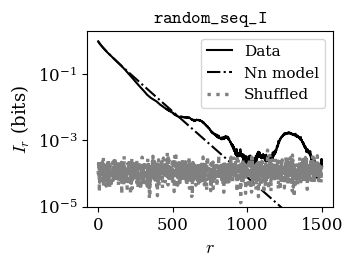

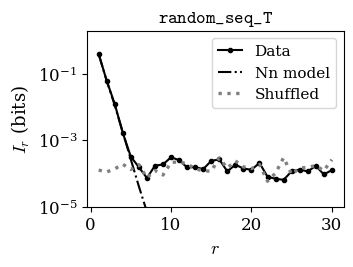

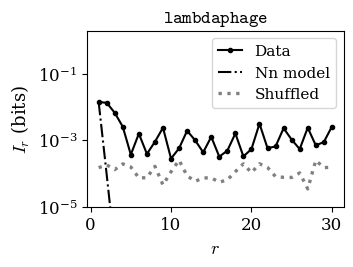

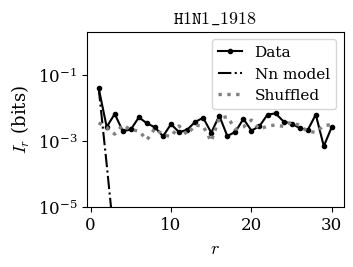

In [23]:
for name in ['random_seq_I', 'random_seq_T', 'lambdaphage', 'H1N1_1918']:
  plt.figure()
  rr=MI[name]['r']
  style = 'o-' if len(rr)<=30 else '-'
  plt.semilogy(rr, MI[name]['data'], style, color='black', markersize=3, label='Data')
  nn=MI[name]['nn']; ok=nn>1e-7
  plt.semilogy(rr[ok], nn[ok], color='black', linestyle='-.', label='Nn model')
  plt.semilogy(rr, MI[name]['shuffled'], color='grey', linestyle=':', linewidth=3, label='Shuffled')
  plt.ylim(1e-5, 2e0)
  plt.legend(loc='upper right')
  plt.title(r'${\tt '+name.replace('_',r'\_')+'}$')
  plt.xlabel(r'$r$')
  plt.ylabel(r'$I_r$ (bits)')
  plt.tight_layout()
  save("MI_"+name+".pdf", HALF)
  plt.show()

## Question 8: conditional compression of the two influenza sequences

$C(y|x) \simeq C(xy)-C(x)$: number of bits needed to encode $y$ once $x$ is known.
Here we encode each base with one ASCII character (one byte per base) and use zstd at its maximum level.

In [25]:
x=seqs['H1N1_1918']
y=seqs['H1N1_2008']

def to_ascii(seq):
  return bytes(''.join('acgt'[i] for i in seq), encoding='ascii')

compressor22 = zstd.ZstdCompressor(level=22)
# Note that the 33-byte overhead of sys.getsizeof cancels in the differences C(xy)-C(x)
def C_ascii(seq):
  return (sys.getsizeof(compressor22.compress(to_ascii(seq))) - sys.getsizeof(b''))*8

# Control: shuffled 2008 sequence
random.seed(2)
y_shuffled=y.copy(); random.shuffle(y_shuffled)

print(f"C(x)/L_x = {C_ascii(x)/len(x):.3f}   C(y)/L_y = {C_ascii(y)/len(y):.3f} bits per base")
for z, zlabel in [(y,'2008'), (y_shuffled,'2008 shuffled')]:
  print(f"z = {zlabel:14s}  C(z|x)/L_z = [C(xz)-C(x)]/L_z = {(C_ascii(x+z)-C_ascii(x))/len(z):.3f} bits per base")

C(x)/L_x = 2.105   C(y)/L_y = 2.129 bits per base
z = 2008            C(z|x)/L_z = [C(xz)-C(x)]/L_z = 0.951 bits per base
z = 2008 shuffled   C(z|x)/L_z = [C(xz)-C(x)]/L_z = 2.059 bits per base


## Summary table

This reproduces the table of the book that summarises the results for the five sequences. In the tables of the book, the probabilities are rounded to the digits shown; when the rounded values of a column do not sum to 1, one of them has been adjusted by one unit in the last digit so that they do: this is the case for the base frequencies of `H1N1_1918` and `H1N1_2008` (e.g. $p(T)=0.2241$ printed here, $0.2242$ in the book), and for the conditional probability $p(T|G)$ of `random_seq_T` ($0.051$ here, $0.052$ in the book).

In [27]:
print(f"{'':10s}" + ''.join(f"{n:>14s}" for n in names))
rows=[('L',lambda n: f"{len(seqs[n])}")]
for a,lab in enumerate('ACGT'):
  rows.append((f'p({lab})', lambda n,a=a: f"{letter_prob(seqs[n])[a]:.4f}"))
rows+= [('H_iid',   lambda n: f"{H_iid[n]:.3f}"),
        ('H_comp',  lambda n: f"{H_comp[n]:.3f}"),
        ('H_shuf',  lambda n: f"{H_shuffle[n]:.3f}"),
        ('p(G|C)',  lambda n: f"{pair_stats(seqs[n])[2][2,1]:.3f}"),
        ('rho_CpG', lambda n: f"{pair_stats(seqs[n])[3][2,1]:.2f}"),
        ('rho_GpC', lambda n: f"{pair_stats(seqs[n])[3][1,2]:.2f}"),
        ('H_nn',    lambda n: f"{H_nn[n]:.3f}")]
for lab,fun in rows:
  print(f"{lab:10s}" + ''.join(f"{fun(n):>14s}" for n in names))

            random_seq_I  random_seq_T   lambdaphage     H1N1_1918     H1N1_2008
L                  50000         50000         48502          2280          2296
p(A)              0.2494        0.3041        0.2543        0.3320        0.3471
p(C)              0.2512        0.0831        0.2343        0.1820        0.1781
p(G)              0.2527        0.3276        0.2643        0.2618        0.2422
p(T)              0.2467        0.2852        0.2471        0.2241        0.2326
H_iid              2.000         1.864         1.999         1.965         1.958
H_comp             1.296         1.589         2.002         2.035         2.035
H_shuf             2.002         1.885         2.002         2.035         2.035
p(G|C)             0.498         0.439         0.274         0.121         0.086
rho_CpG             1.97          1.34          1.04          0.46          0.35
rho_GpC             1.97          0.59          1.20          0.88          0.91
H_nn               1.025    